### 1. Yếu tố Tài chính
Ngân sách sản xuất (budget) và doanh thu phòng vé (revenue) có mối quan hệ như thế nào với rating trung bình của phim do người dùng MovieLens đánh giá?

#### a. Phân tích tương quan

In [121]:
# --- BƯỚC TÍNH HỆ SỐ TƯƠNG QUAN (ĐÃ ĐIỀU CHỈNH) ---

# 1. Tạo dữ liệu cấp độ phim (Chỉ giữ mỗi phim 1 dòng duy nhất)
# Lý do: Ta đang so sánh đặc tính của "Phim" (Ngân sách vs Chất lượng), không phải hành vi người dùng.
df_movie_scope = full_data.drop_duplicates(subset=['MovieID'])

# 2. Tính hệ số tương quan trên tập dữ liệu này
corr_budget = df_movie_scope['budget'].corr(df_movie_scope['avg_rating'])
corr_revenue = df_movie_scope['revenue'].corr(df_movie_scope['avg_rating'])

# 3. In kết quả
print(f"Hệ số tương quan (Pearson) trên {df_movie_scope.shape[0]} bộ phim:")
print(f"- Budget  vs avg_rating: {corr_budget:.4f}")
print(f"- Revenue vs avg_rating: {corr_revenue:.4f}")

# Giải thích nhanh kết quả
if corr_budget < 0:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.")
else:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng TĂNG.")

Hệ số tương quan (Pearson) trên 617 bộ phim:
- Budget  vs avg_rating: -0.1879
- Revenue vs avg_rating: 0.1122
-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.


Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:
$$
r_{XY} = 
\frac{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}
{\sqrt{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})^2 } \;
 \sqrt{\displaystyle \sum_{i=1}^{n} (Y_i - \bar{Y})^2 }}
$$

##### Ý nghĩa

**Tử số:**

$$
\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})
$$

Đo mức độ mà X và Y cùng tăng hoặc cùng giảm:

- Nếu X tăng → Y cũng tăng → tích số dương  
- Nếu X tăng → Y giảm → tích số âm  

**Mẫu số:**

$$
\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 } \cdot 
\sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2 }
$$

Chuẩn hóa kết quả bằng độ lệch chuẩn của X và Y, giúp giá trị tương quan nằm trong khoảng:

$$
-1 \le r \le 1
$$


##### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

##### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

#### b. Trực quan hóa

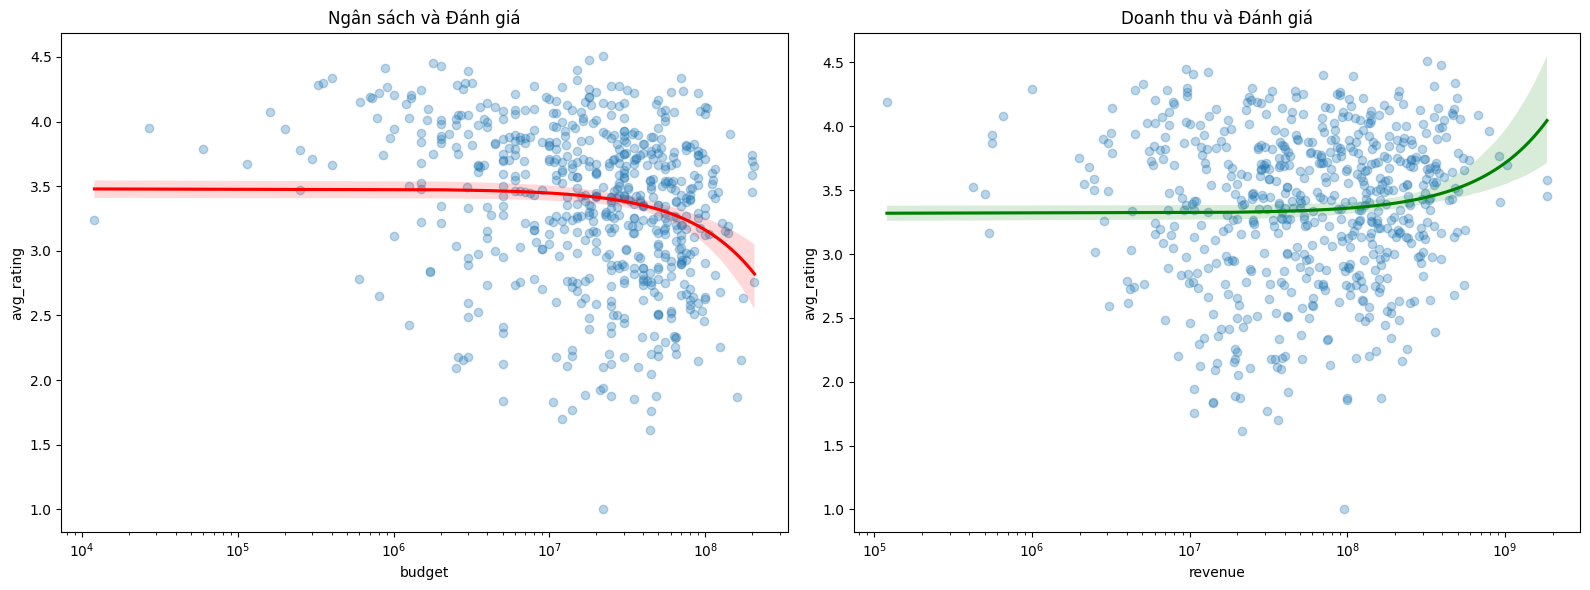

In [122]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.savefig('images/correlation_analysis.png')
plt.show()


Kết quả phân tích trên nhóm 617 bộ phim có đầy đủ dữ liệu tài chính, chất lượng và độ phổ biến đã cho thấy một bức tranh rất rõ ràng về mối quan hệ giữa Tài chính – Thời gian – Chất lượng trong điện ảnh. Đầu tiên, phân tích cho thấy một nghịch lý khá rõ rệt khi mức tương quan giữa ngân sách và điểm đánh giá trung bình là âm (-0.19). Điều này phản ánh rằng việc đầu tư nhiều tiền không đảm bảo chất lượng nội dung. Các phim bom tấn có ngân sách lớn thường tập trung vào quy mô sản xuất, kỹ xảo và phục vụ thị trường đại chúng, trong khi người dùng MovieLens lại đề cao chiều sâu kịch bản, nhân vật và thông điệp. Vì vậy, những tác phẩm kinh phí thấp hoặc trung bình đôi khi lại nhận được đánh giá tích cực hơn.

Ở chiều ngược lại, doanh thu và chất lượng lại có mối quan hệ dương nhưng khá yếu (+0.11). Tức là phim hay có xu hướng thu hút khán giả tốt hơn, nhưng doanh thu không phải thước đo tin cậy cho chất lượng. Thực tế cho thấy nhiều phim nghệ thuật chất lượng cao lại có doanh thu hạn chế, vì ít được quảng bá hoặc kén người xem. Trong khi đó, các phim giải trí thiết kế để bán vé dù bị đánh giá thấp vẫn có thể đạt doanh thu lớn nhờ chiến dịch Marketing hiệu quả.

Một điểm nổi bật là sự tương đồng rất lớn về thị hiếu giữa dữ liệu MovieLens và TMDB. Tương quan +0.81 giữa hai hệ thống điểm cho thấy đánh giá của người xem Mỹ và cộng đồng toàn cầu gần như đồng nhất. Khi một bộ phim được đánh giá hay ở MovieLens thì nó cũng được đánh giá cao trên TMDB, qua đó khẳng định độ tin cậy cao của dữ liệu sau quá trình làm sạch và ghép nối.

Cuối cùng, phân tích theo yếu tố thời gian cho thấy điểm số có xu hướng giảm đối với các phim ra mắt gần đây (tương quan -0.35). Tuy nhiên, nguyên nhân chính nằm ở hiệu ứng "Thiên kiến kẻ sống sót". Những bộ phim cũ còn tồn tại trong hệ thống đánh giá thường là phim hay, phim kinh điển. Các tác phẩm yếu kém của thời kỳ đó đã gần như biến mất khỏi dữ liệu. Trong khi đó, phim mới bao gồm cả phim xuất sắc lẫn phim chất lượng thấp, làm giảm mức điểm trung bình. Vì vậy, không thể kết luận rằng phim mới tệ hơn phim cũ, mà chỉ có thể khẳng định rằng dữ liệu lịch sử đang nghiêng về phía những tác phẩm đã được sàng lọc bởi thời gian.

--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---
                               mean  count
Budget_Category                           
Micro/Indie\n(<$10M)       3.597960    170
Mid-Budget\n($10M-$50M)    3.296988    298
High-Budget\n($50M-$100M)  3.252201    123
Blockbuster\n(>$100M)      3.221133     26


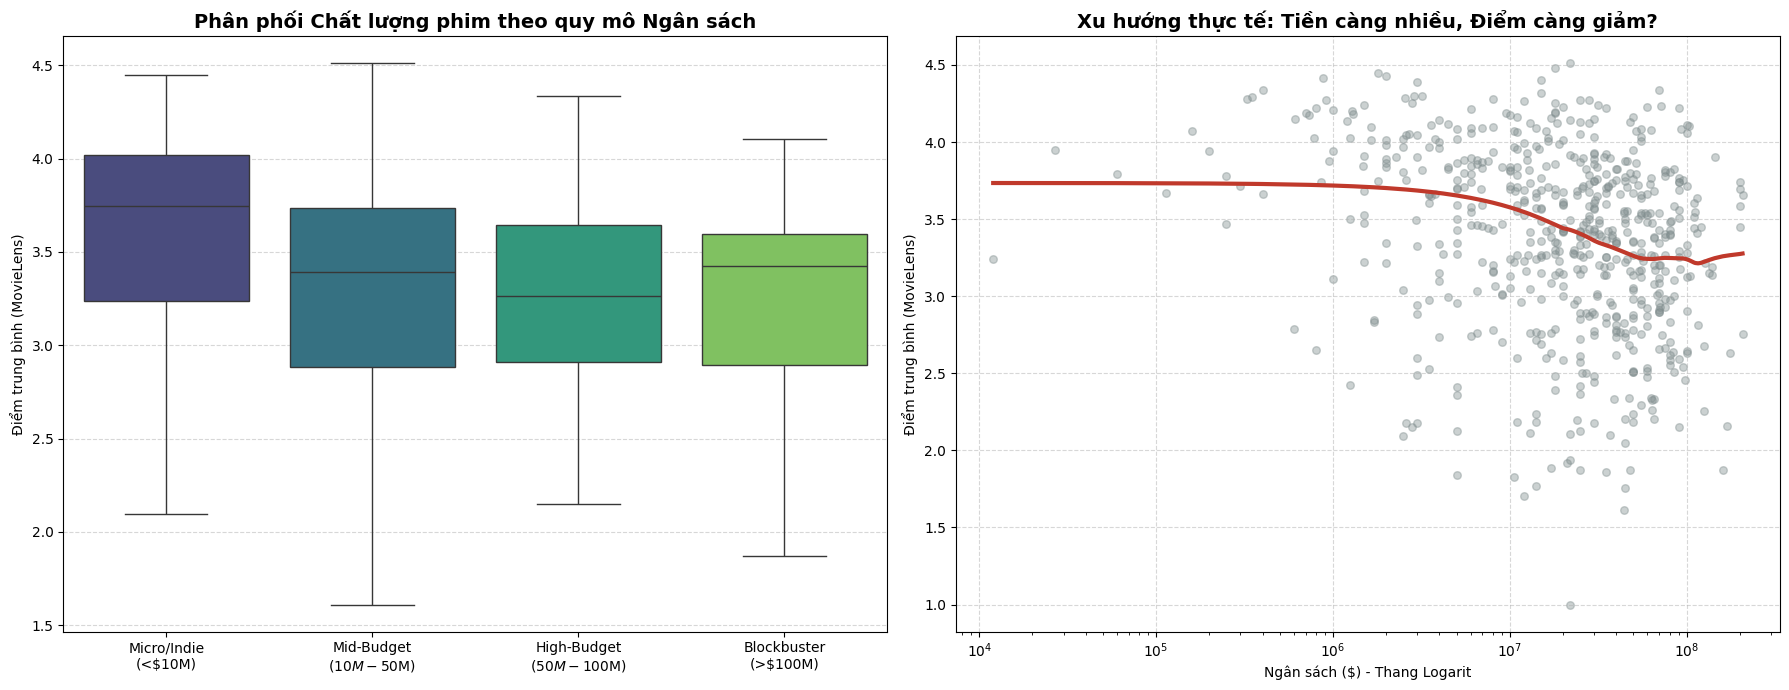

In [123]:
# --- BƯỚC 1: PHÂN NHÓM NGÂN SÁCH (BUDGET BUCKETS) ---
# Chia ngân sách thành 4 nhóm chiến lược
bins = [0, 10000000, 50000000, 100000000, float('inf')]
labels = ['Micro/Indie\n(<$10M)', 'Mid-Budget\n($10M-$50M)', 'High-Budget\n($50M-$100M)', 'Blockbuster\n(>$100M)']

# Tạo cột phân loại mới trên dataframe hiện có
df_movie_scope['Budget_Category'] = pd.cut(df_movie_scope['budget'], bins=bins, labels=labels)

# Tính điểm trung bình cho từng nhóm để so sánh
group_stats = df_movie_scope.groupby('Budget_Category')['avg_rating'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---")
print(group_stats)

# --- BƯỚC 2: TRỰC QUAN HÓA PHI TUYẾN TÍNH ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Boxplot (So sánh phân phối điểm số)
sns.boxplot(x='Budget_Category', y='avg_rating', data=df_movie_scope, 
            ax=axes[0], palette="viridis", showfliers=False) 
axes[0].set_title('Phân phối Chất lượng phim theo quy mô Ngân sách', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Điểm trung bình (MovieLens)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ 2: Scatter Plot với đường cong LOWESS (Non-linear trend)
sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, 
            ax=axes[1], 
            scatter_kws={'alpha': 0.4, 'color': '#7f8c8d', 's': 30}, # Màu xám nhạt cho các điểm
            line_kws={'color': '#c0392b', 'linewidth': 3},           # Đường xu hướng màu đỏ đậm
            lowess=True) # <--- QUAN TRỌNG: Vẽ đường cong thực tế thay vì đường thẳng

axes[1].set_title('Xu hướng thực tế: Tiền càng nhiều, Điểm càng giảm?', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Ngân sách ($) - Thang Logarit')
axes[1].set_ylabel('Điểm trung bình (MovieLens)')
axes[1].set_xscale('log') # Dùng thang Log để giãn cách dữ liệu cho dễ nhìn
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('images/budget_vs_quality.png')
plt.show()

Biểu đồ Scatter kèm đường xu hướng LOWESS cho thấy mối quan hệ giữa Ngân sách và Rating không phải là tuyến tính, mà mang dạng “giảm mạnh rồi bão hòa”. Ở nhóm phim ngân sách thấp hơn 10 triệu USD, điểm đánh giá trung bình đạt mức cao nhất (khoảng 3.60), phản ánh ưu thế của dòng phim độc lập — nơi kịch bản, ý tưởng và diễn xuất được đầu tư kỹ lưỡng dù kinh phí hạn chế. Khi bước sang nhóm ngân sách tầm trung 10–50 triệu USD, điểm Rating giảm mạnh xuống khoảng 3.30. Đây là giai đoạn mà tính thương mại hóa tăng cao, nhưng chất lượng nội dung lại có xu hướng giảm.

Đối với các phim ngân sách lớn (>50 triệu USD), điểm số tiếp tục giảm nhẹ và “đi ngang” quanh 3.22–3.25. Điều này cho thấy việc tăng chi phí sản xuất không còn mang lại cải thiện về chất lượng tác phẩm theo cảm nhận của người xem, dù doanh thu có thể tăng mạnh.

#### c. Phân cụm K-Means

Câu hỏi phụ 1: Mối quan hệ giữa ngân sách và rating có đồng nhất cho tất cả các bộ phim, hay khác biệt đáng kể giữa các nhóm phim có đặc điểm tài chính – nội dung khác nhau?

Phân cụm (Clustering - K-Means)

Sử dụng thuật toán K-Means để chia các bộ phim thành 3 nhóm (cluster).

Kết quả thống kê:
 + Cụm 0 (Cluster 0): Ngân sách trung bình (~42M), thời lượng ~111 phút, Rating thấp nhất (~3.12).
 + Cụm 1 (Cluster 1): Ngân sách cao nhất (~67M), độ phổ biến cao nhất. Rating trung bình (~3.30). Đây có thể là nhóm phim bom tấn giải trí.
 + Cụm 2 (Cluster 2): Ngân sách thấp nhất (~23M), thời lượng dài nhất (~116 phút). Rating cao nhất (~3.50). Đây chính là nhóm phim "nghệ thuật" kinh phí thấp mà chúng ta đã thảo luận.


Data ready. Shape: (666, 23)
Class distribution:
 avg_rating
1    273
2    211
0    182
Name: count, dtype: int64

=== 2. Improved K-Means Clustering ===
Inertia for K values: [14075.374633353465, 12934.25815363176, 12135.720506537133, 11467.61048678209, 10859.954972596326, 10187.30668065251]
Silhouette scores: [0.15382096000153114, 0.1446669754826244, 0.11166233916153091, 0.13281069560809258, 0.1403345967932928, 0.17557676841327594]

Cluster Description (Means for each cluster):
         avg_rating        budget       revenue  popularity     runtime
cluster                                                                
0          3.214035  5.430395e+07  1.790746e+08   33.704677  116.306533
1          3.217818  5.528659e+07  2.186820e+08   36.916655   96.333333
2          3.414838  2.095793e+07  7.182585e+07   21.210703  114.174224


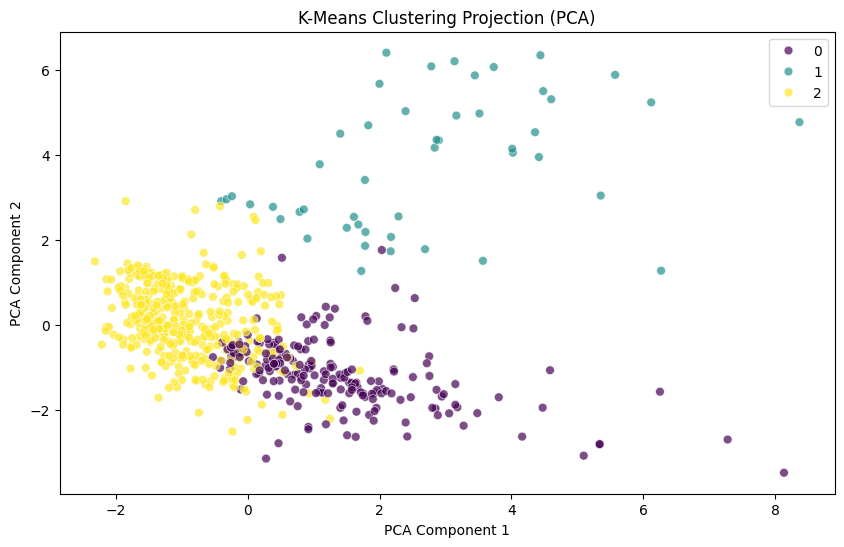

In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    
    # Target for Classification (Binning)
    # < 3.0: Low (0), 3.0 - 3.8: Medium (1), >= 3.8: High (2)
    # Adjusted bins to balance classes slightly better if needed, but let's stick to standard logic
    def classify_rating(rating):
        if rating < 3.0: return 0 # Low
        elif rating < 3.7: return 1 # Medium (MovieLens average is around 3.5)
        else: return 2 # High

    y_class = df_model['avg_rating'].apply(classify_rating)
    class_names = ['Low (<3.0)', 'Medium (3.0-3.7)', 'High (>=3.7)']

    print(f"Data ready. Shape: {X.shape}")
    print("Class distribution:\n", y_class.value_counts())

except Exception as e:
    print(f"Error preparing data: {e}")

# ------------------------------------------------------------
# 2. CLUSTERING (K-Means Rewritten and Improved)
# ------------------------------------------------------------
print("\n=== 2. Improved K-Means Clustering ===")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 2.1 Scale toàn bộ feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2 Tìm số cụm tối ưu bằng Elbow + Silhouette
inertia_list = []
silhouette_list = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, preds))

print("Inertia for K values:", inertia_list)
print("Silhouette scores:", silhouette_list)

# 2.3 Chọn K=3 (dựa vào domain knowledge: low–mid–high movie type)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_model['cluster'] = clusters

# 2.4 Thống kê các cụm
cluster_desc = df_model.groupby('cluster')[['avg_rating', 'budget', 'revenue', 
                                            'popularity', 'runtime']].mean()

print("\nCluster Description (Means for each cluster):")
print(cluster_desc)

# 2.5 PCA Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=clusters, palette='viridis', s=40, alpha=0.7
)
plt.title("K-Means Clustering Projection (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.savefig("images/kmeans_pca.png")
plt.show()

Quan sát chính từ biểu đồ

Ba cụm phim được tách biệt tương đối rõ ràng

Các điểm dữ liệu hình thành ba vùng riêng biệt, cho thấy thuật toán K-Means đã xác định được các nhóm phim có đặc trưng khác nhau trong không gian đặc trưng ban đầu.

 + Cluster 2 (màu vàng): Tập trung dày đặc ở vùng PCA thấp → nhóm phim có đặc trưng tương đối đồng nhất, thường là phim ngân sách thấp – trung bình, ít biến động.
 + Cluster 0 (màu tím): Phân bố trải dài theo trục PCA Component 1 → nhóm phim có độ đa dạng cao hơn, có thể bao gồm nhiều mức ngân sách và độ phổ biến khác nhau.
 + Cluster 1 (màu xanh lục): Xuất hiện ở vùng PCA Component 2 cao → nhóm phim có đặc điểm nổi bật về tài chính và độ phổ biến, thường tương ứng với phim ngân sách lớn / phim bom tấn.

Trả lời câu hỏi phụ 1: 

    -> Biểu đồ này củng cố giả thuyết rằng:
        + Không tồn tại một “mô hình phim duy nhất” quyết định rating
        + Các bộ phim có thể được chia thành những nhóm tài chính – nội dung khác nhau

        Do đó, việc phân tích mối quan hệ giữa Budget / Revenue và Rating cần được thực hiện theo từng cụm, thay vì trên toàn bộ tập dữ liệu

#### d. Linear Regression theo từng cụm

Câu hỏi phụ 2: Việc tăng ngân sách sản xuất có luôn dẫn đến rating cao hơn, hay tồn tại hiện tượng “hiệu quả giảm dần”, trong đó các phim có ngân sách thấp–trung bình lại đạt rating cao hơn?

In [125]:
# Chạy cell này đầu tiên (nếu chưa import)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
%matplotlib inline

Chuẩn bị biến và lựa chọn biến độc lập

In [126]:
# Tạo biến log_budget, log_revenue để ổn định phân phối
df_model['log_budget'] = np.log1p(df_model['budget'])
df_model['log_revenue'] = np.log1p(df_model['revenue'])

# Các biến độc lập cơ bản (bạn có thể thêm/dớt genres, runtime, popularity...)
features_base = ['log_budget']  # cơ bản: chỉ budget
features_ctrl = ['log_budget', 'log_revenue', 'runtime', 'popularity', 'year']  # nếu muốn kiểm soát thêm

# Target
target = 'avg_rating'

Hàm chạy OLS cho từng cụm và in summary

In [127]:
def run_cluster_ols(df, cluster_col='cluster', features=None, target='avg_rating', add_constant=True, save_summary=False):
    """
    Chạy OLS cho từng cluster. Trả về dict chứa kết quả statsmodels.
    """
    results = {}
    clusters = sorted(df[cluster_col].unique())
    for c in clusters:
        sub = df[df[cluster_col] == c].dropna(subset=features + [target])
        if sub.shape[0] < 10:
            print(f"Cluster {c}: quá ít mẫu ({sub.shape[0]}) — bỏ qua.")
            continue
        
        X = sub[features].copy()
        if add_constant:
            X = sm.add_constant(X)
        y = sub[target]
        
        model = sm.OLS(y, X).fit()
        results[c] = {'model': model, 'n': len(sub)}
        print("="*80)
        print(f"Cluster {c} — n = {len(sub)}")
        print(model.summary())
        print("\n")
        if save_summary:
            with open(f"ols_cluster_{c}_summary.txt", "w", encoding="utf-8") as f:
                f.write(model.summary().as_text())
    return results

# Ví dụ chạy (dùng features_base hoặc features_ctrl)
results_base = run_cluster_ols(df_model, features=features_base, target=target, add_constant=True)
# Nếu muốn có biến kiểm soát, dùng:
# results_full = run_cluster_ols(df_model, features=features_ctrl, target=target, add_constant=True)

Cluster 0 — n = 199
                            OLS Regression Results                            
Dep. Variable:             avg_rating   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     5.955
Date:                Fri, 19 Dec 2025   Prob (F-statistic):             0.0156
Time:                        23:45:55   Log-Likelihood:                -170.79
No. Observations:                 199   AIC:                             345.6
Df Residuals:                     197   BIC:                             352.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6520      0.591

Vẽ scatter + đường hồi quy cho từng cụm (log_budget vs avg_rating)

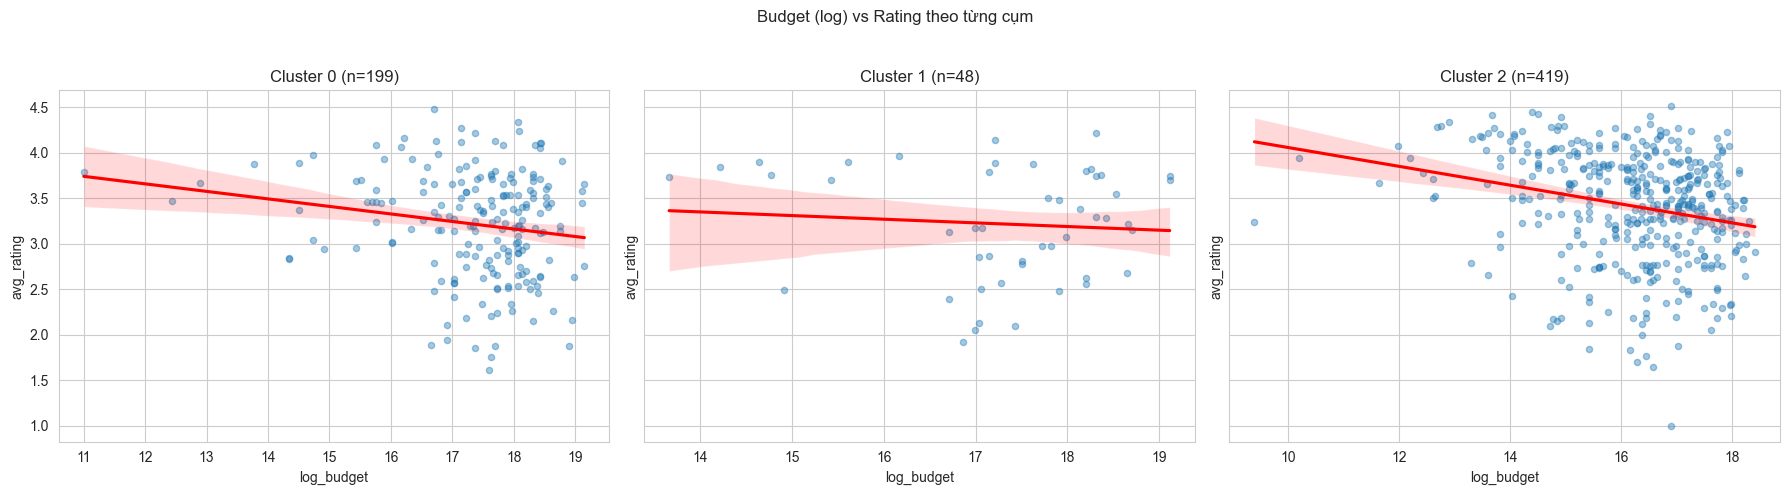

In [128]:
# Scatter + regression line (seaborn regplot) cho từng cluster
clusters = sorted(df_model['cluster'].unique())
n = len(clusters)
fig, axes = plt.subplots(1, n, figsize=(6*n, 5), sharey=True)

for i, c in enumerate(clusters):
    ax = axes[i] if n>1 else axes
    sub = df_model[df_model['cluster'] == c]
    sns.regplot(x='log_budget', y='avg_rating', data=sub, scatter_kws={'s':20, 'alpha':0.4}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'Cluster {c} (n={len(sub)})')
    ax.set_xlabel('log_budget')
    if i==0:
        ax.set_ylabel('avg_rating')

plt.suptitle('Budget (log) vs Rating theo từng cụm')
plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig('images/clusterwise_budget_vs_rating.png', dpi=150)
plt.show()

Kết quả quan sát theo từng cụm

Cluster 0 (n = 199) – Ngân sách trung bình đến cao

Đường hồi quy có độ dốc âm rõ rệt, cho thấy khi ngân sách tăng, rating trung bình có xu hướng giảm nhẹ. Mặc dù tồn tại một số phim ngân sách cao đạt rating tốt, nhưng xu hướng tổng thể không ủng hộ giả thuyết “ngân sách cao hơn → rating cao hơn”.

Cluster 1 (n = 48) – Phim ngân sách lớn / phim bom tấn

Mối quan hệ giữa ngân sách và rating trong cụm này gần như phẳng, với độ dốc âm rất nhỏ và vùng tin cậy rộng. Điều này cho thấy ngân sách không phải yếu tố quyết định rating đối với các phim bom tấn; việc đầu tư thêm chi phí sản xuất không đảm bảo cải thiện đánh giá từ người xem.

Cluster 2 (n = 419) – Phim ngân sách thấp đến trung bình

Cụm này thể hiện xu hướng âm mạnh nhất: rating trung bình giảm đáng kể khi ngân sách tăng. Đáng chú ý, nhiều phim có ngân sách thấp–trung bình đạt rating cao nhất trong toàn bộ dữ liệu, cho thấy hiệu quả đầu tư không tỷ lệ thuận với chất lượng cảm nhận của người xem.

Residual plots và kiểm tra cơ bản cho mỗi model

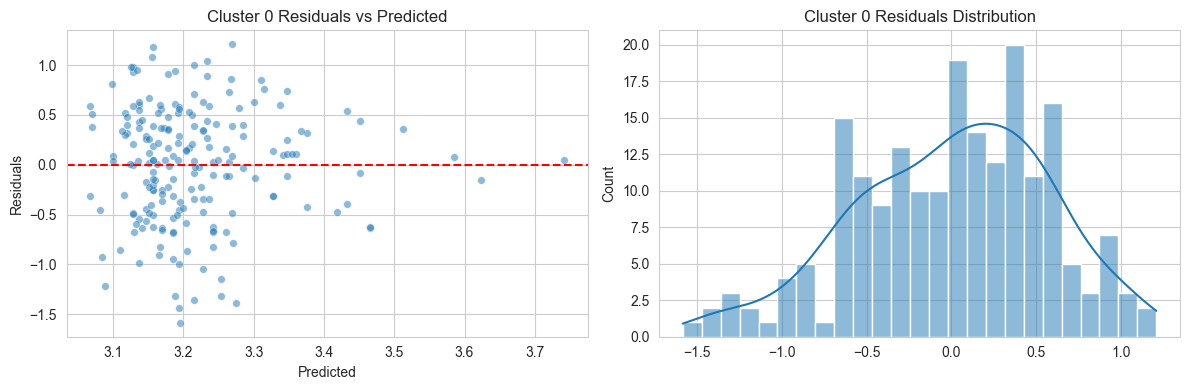

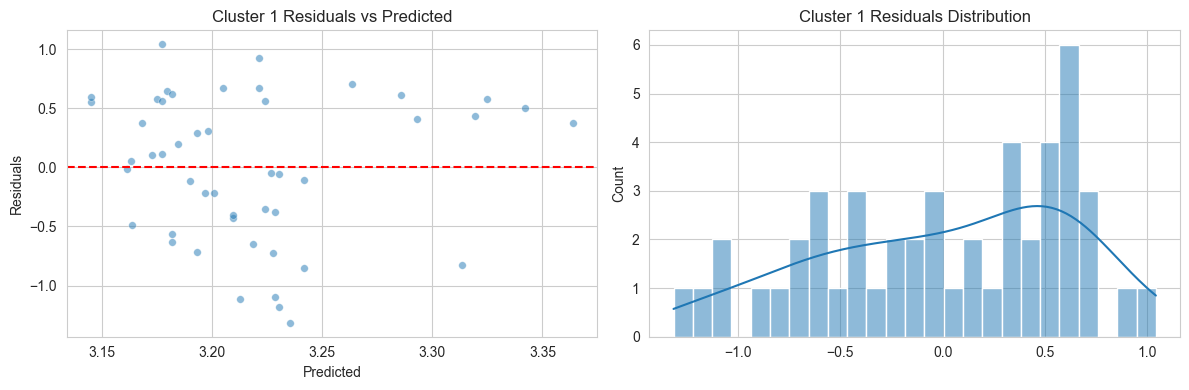

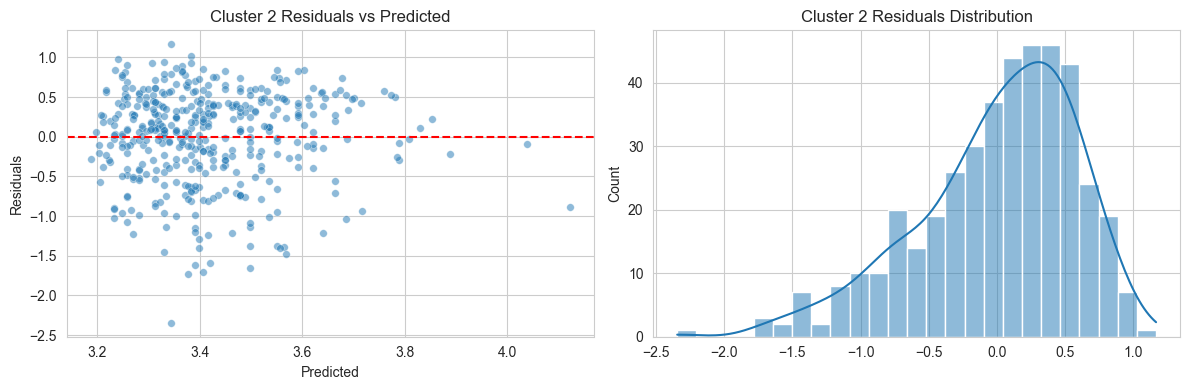

In [129]:
# Residual plot: predicted vs residuals, và histogram residuals
for c, resdict in results_base.items():
    model = resdict['model']
    sub = df_model[df_model['cluster'] == c].dropna(subset=features_base + [target])
    X = sm.add_constant(sub[features_base])
    y = sub[target]
    preds = model.predict(X)
    residuals = y - preds
    
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    sns.scatterplot(x=preds, y=residuals, ax=axes[0], s=30, alpha=0.5)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title(f'Cluster {c} Residuals vs Predicted')
    
    sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
    axes[1].set_title(f'Cluster {c} Residuals Distribution')
    plt.tight_layout()
    plt.savefig(f'images/cluster_{c}_residuals.png', dpi=150)
    plt.show()


Kiểm định độ phù hợp mô hình qua Residuals
Biểu đồ residuals của từng cụm cho thấy:
 + Phần dư phân bố quanh 0, không có xu hướng lệch hệ thống.
 + Histogram residuals gần dạng phân phối chuẩn.

Điều này cho thấy kết luận về mối quan hệ âm giữa ngân sách và rating không phải là nhiễu ngẫu nhiên, mà phản ánh một xu hướng ổn định trong dữ liệu.

So sánh hệ số (coefficients) giữa các cụm

   cluster    n  coef_log_budget  pvalue_log_budget        r2
0        0  199        -0.082746       1.556127e-02  0.029341
1        1   48        -0.040149       5.749624e-01  0.006887
2        2  419        -0.103458       8.521060e-07  0.056529


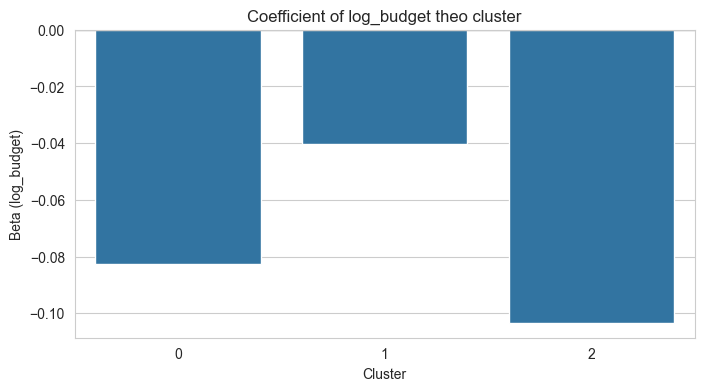

In [130]:
# Lấy hệ số beta và p-value cho mỗi cluster
rows = []
for c, resdict in results_base.items():
    model = resdict['model']
    params = model.params
    pvalues = model.pvalues
    rows.append({
        'cluster': c,
        'n': resdict['n'],
        'coef_log_budget': params.get('log_budget', np.nan),
        'pvalue_log_budget': pvalues.get('log_budget', np.nan),
        'r2': model.rsquared
    })

coef_df = pd.DataFrame(rows).sort_values('cluster')
print(coef_df)

# Vẽ bar plot hệ số
plt.figure(figsize=(8,4))
sns.barplot(x='cluster', y='coef_log_budget', data=coef_df)
plt.title('Coefficient of log_budget theo cluster')
plt.xlabel('Cluster')
plt.ylabel('Beta (log_budget)')
plt.axhline(0, color='black', linewidth=0.8)
plt.savefig('images/coef_log_budget_by_cluster.png', dpi=150)
plt.show()

In [131]:
coef_df.to_csv('result/clusterwise_regression_results.csv', index=False)

Diễn giải:

1. Mỗi cluster sẽ có bảng model.summary() (từ statsmodels) gồm: hệ số (coef), độ lệch chuẩn, t-stat, p-value, R², adj. R².

2. Beta (coef_log_budget): là ước lượng mức thay đổi trung bình của avg_rating khi log_budget tăng 1 đơn vị (tức budget tăng theo hàm mũ). Nếu beta dương và p-value < 0.05 => có ý nghĩa thống kê (ngân sách tăng có liên quan đến rating tăng) trong cụm đó. Nếu p-value lớn => không đủ bằng chứng.

3. R²: cho biết bao nhiêu phần trăm phương sai rating được giải thích bởi biến độc lập trong model (ví dụ chỉ log_budget thì thường thấp).

4. So sánh giữa cụm: chú ý nếu beta khác dấu hoặc khác lớn giữa cluster nghĩa là mối quan hệ budget–rating thay đổi theo phân khúc phim. Ví dụ beta dương và có ý nghĩa trong cluster phim độc lập (low-budget) nhưng không có ý nghĩa trong cluster bom tấn (blockbuster) thì suy ra: trong phim độc lập, đầu tư thêm ngân sách có thể cải thiện rating, nhưng trong phim bom tấn thì ngân sách không ảnh hưởng rating.

#### e. Phân tích Hệ số (Coefficient Analysis)

Biểu đồ hệ số cho thấy beta của log(budget) đều âm ở cả ba cụm, trong đó:
 + Cụm 2 có hệ số âm lớn nhất → tác động tiêu cực của ngân sách cao đến rating rõ ràng nhất.
 + Cụm 0 có hệ số âm ở mức trung bình.
 + Cụm 1 có hệ số âm nhỏ nhất, cho thấy ngân sách cao gần như không còn ảnh hưởng đáng kể đến rating.

Về mặt định lượng, điều này khẳng định rằng sau một ngưỡng nhất định, việc tăng ngân sách mang lại hiệu quả biên rất thấp, thậm chí âm, đối với rating người dùng.

Trả lời câu hỏi phụ 2:

    -> Việc tăng ngân sách sản xuất không luôn dẫn đến rating cao hơn. Ngược lại, dữ liệu cho thấy tồn tại rõ ràng hiện tượng “hiệu quả giảm dần” (diminishing returns). Các phim có ngân sách thấp đến trung bình thường đạt rating cao hơn so với nhiều phim ngân sách lớn, đặc biệt trong nhóm phim đại chúng.

##### Insight rút ra

Ngân sách lớn ≠ chất lượng cảm nhận cao: Người dùng MovieLens đánh giá cao nội dung, câu chuyện và chiều sâu hơn là quy mô đầu tư tài chính.

Phim kinh phí vừa phải có lợi thế về rating: Đây thường là các phim tập trung vào kịch bản và nghệ thuật, phù hợp với thị hiếu đánh giá của người xem.

Ngân sách cao chủ yếu phục vụ doanh thu và độ phủ, chứ không phải để tối ưu điểm rating.

##### Kết luận và trả lời câu hỏi lớn
Kết quả phân tích cho thấy ngân sách sản xuất (budget) và doanh thu phòng vé (revenue) không có mối quan hệ tích cực rõ ràng với rating trung bình của phim do người dùng MovieLens đánh giá. Ngược lại, mối quan hệ này có xu hướng yếu và mang dấu âm nhẹ, đặc biệt khi xem xét ở cấp độ từng nhóm phim có đặc trưng tương đồng.

Cụ thể, phân tích tương quan Pearson trên dữ liệu cấp độ phim cho thấy cả budget và revenue đều có hệ số tương quan thấp với avg_rating, cho thấy yếu tố tài chính chỉ giải thích được một phần rất nhỏ sự biến thiên trong đánh giá người dùng. Điều này bác bỏ giả định trực giác rằng phim đầu tư nhiều tiền hoặc thu về doanh thu lớn sẽ luôn được đánh giá cao hơn.

Khi đi sâu hơn bằng phương pháp phân cụm K-Means, các phim được chia thành các nhóm có cấu trúc tài chính và đặc điểm nội dung khác nhau. Trong cả ba cụm, hồi quy tuyến tính giữa log(budget) và rating đều cho hệ số âm, cho thấy sau một ngưỡng nhất định, việc tăng ngân sách không giúp cải thiện rating, thậm chí còn làm giảm nhẹ điểm đánh giá trung bình. Hiện tượng này phản ánh rõ “hiệu quả giảm dần” của ngân sách đối với chất lượng cảm nhận của người xem.

Doanh thu phòng vé cũng thể hiện một xu hướng tương tự. Phim doanh thu cao thường là phim có độ phủ truyền thông lớn hoặc hướng đến thị trường đại chúng, nhưng điều đó không đồng nghĩa với việc được đánh giá cao hơn về mặt chất lượng. Rating trên MovieLens phản ánh đánh giá hậu nghiệm của người xem, trong khi doanh thu chủ yếu phản ánh mức độ tiếp cận và thành công thương mại.